# 06 · Robustez y validación del modelo

Los cuadernos 02 a 05 compararon algoritmos con una partición aleatoria del mismo periodo. Este cuaderno responde a las preguntas que haría un revisor antes de aceptar esos resultados en un artículo:

| Pregunta del revisor | Análisis | Sección |
|---|---|---|
| ¿Cuánto aportan las 34 variables frente a lo que sabe un médico de un vistazo? | **Modelos de referencia** (solo edad y sexo; clínico mínimo) | 4 |
| ¿El modelo sirve para decidir algo, o solo ordena bien? | **Curva de decisión** (*decision curve analysis*, beneficio neto) | 5 |
| ¿El modelo predice complicaciones o predice quién va más al establecimiento? | **Objetivos alternativos**: solo eventos graves, sin N17, por tipo de evento | 6 |
| ¿Sigue funcionando con pacientes de un año posterior? | **Validación temporal**: entrenar con 2022 → 2023 y evaluar con 2023 → 2024 | 7 |
| ¿El reporte cumple el estándar? | **Checklist TRIPOD+AI** | 8 |

**Hipótesis planteadas antes de ejecutar** (para contrastarlas con los resultados, no para ajustarlas después):

1. El modelo clínico mínimo se acerca al completo (ROC-AUC ≈ 0.66-0.68). Las variables de uso del sistema aportan unos pocos puntos más.
2. El beneficio neto del Random Forest supera a "seguir a todos" entre los umbrales de 3% y 15%, que son los clínicamente razonables para un seguimiento de bajo costo.
3. Con `y_grave` el ROC-AUC se mantiene o sube, y pierden peso `prop_capita` y `n_atenciones`. Si ocurre lo contrario, buena parte de la señal actual sería sesgo de detección.
4. En la validación temporal el ROC-AUC cae menos de 0.02 frente a la validación interna, pero la calibración se desplaza porque el volumen de atenciones crece cada año.

> **Requisitos.** `data/processed/dataset_consolidado.csv` (de `src/preprocessing.ipynb`), los datos crudos en `data/raw/` y el módulo `src/preprocessing.py`. La sección 2 lee los datos crudos **una sola vez** y guarda las cohortes nuevas; en las siguientes ejecuciones se reutilizan.

## 1. Inicializar

In [1]:
import gc
import sys
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.optimize import brentq

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve

SEED = 42

AZUL, NARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GRIS, TEXTO, TEXTO_2 = '#a3a29b', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ad',
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlecolor': TEXTO, 'axes.labelcolor': TEXTO_2,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False,
})

def cronometro(t0):
    return f"{(time.time() - t0) / 60:.1f} min"

In [2]:
# --- Parámetros del trabajo ---
RUTA_MANUAL_DATASET = None   # ruta completa de dataset_consolidado.csv, si no está en data/processed/
RUTA_MANUAL_RAW = None       # carpeta de los datos crudos, si no están en data/raw/
RUTA_MANUAL_SRC = None       # ruta completa de preprocessing.py, si no está en src/
RECONSTRUIR_COHORTES = False # True = volver a leer los datos crudos aunque ya existan las cohortes guardadas

N_ARBOLES = 300              # árboles de cada Random Forest (el cuaderno entrena 7). 100 para una prueba rápida
N_BOOT = 500                 # remuestreos bootstrap para los intervalos de confianza
# Mejores hiperparámetros de 03_random_forest.ipynb (sin class_weight: así las probabilidades quedan calibradas)
PARAMS_RF = dict(min_samples_leaf=50, max_samples=0.3, max_features=0.5, max_depth=16, class_weight=None)
C_RL = 0.01                  # regularización de la regresión logística (02_modelos.ipynb)
OBJETIVOS_REENTRENAR = ['y_grave', 'y_sin_n17', 'y_cardiovascular', 'y_erc', 'y_fallecido']

def buscar_dataset(nombre='dataset_consolidado.csv'):
    if RUTA_MANUAL_DATASET:
        return Path(RUTA_MANUAL_DATASET)
    for p in [Path.cwd(), *Path.cwd().parents]:
        for d in (p, p / 'data' / 'processed'):
            if (d / nombre).exists():
                return d / nombre
    raise FileNotFoundError(f"No se encontró {nombre}. Ejecuta primero src/preprocessing.ipynb o usa RUTA_MANUAL_DATASET.")

RUTA_DATASET = buscar_dataset()
RUTA_PROC = RUTA_DATASET.parent
RAIZ = RUTA_PROC.parents[1] if RUTA_PROC.name == 'processed' and RUTA_PROC.parent.name == 'data' else RUTA_PROC
RUTA_RESULTADOS = RAIZ / 'results' if (RAIZ / 'data').is_dir() else RUTA_PROC
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

# El módulo src/preprocessing.py (misma lógica que src/preprocessing.ipynb, con ventanas de tiempo parametrizables)
def buscar_modulo():
    if RUTA_MANUAL_SRC:
        return Path(RUTA_MANUAL_SRC)
    # 1) carpeta del cuaderno, src/ y carpetas superiores
    for p in [Path.cwd(), *Path.cwd().parents, RAIZ]:
        for d in (p, p / 'src'):
            if (d / 'preprocessing.py').is_file():
                return d / 'preprocessing.py'
    # 2) cualquier subcarpeta del proyecto, aunque el navegador lo haya renombrado ("preprocessing (1).py", ".py.txt")
    for base in [RAIZ, Path.cwd().parent]:
        candidatos = sorted(x for x in base.rglob('preprocessing*.py*') if x.is_file() and x.suffix in ('.py', '.txt'))
        if candidatos:
            return candidatos[0]
    raise FileNotFoundError(
        "No se encontró src/preprocessing.py. Cópialo en la carpeta src/ del proyecto (al lado de preprocessing.ipynb) "
        "o escribe su ruta completa en RUTA_MANUAL_SRC.")

import importlib.util
RUTA_MODULO = buscar_modulo()
if RUTA_MODULO.name != 'preprocessing.py':
    print(f"Aviso: se usa {RUTA_MODULO.name}; conviene renombrarlo a preprocessing.py")
_spec = importlib.util.spec_from_file_location('preprocessing', RUTA_MODULO)
preprocessing = importlib.util.module_from_spec(_spec)
sys.modules['preprocessing'] = preprocessing
_spec.loader.exec_module(preprocessing)
print("Módulo cargado desde:", RUTA_MODULO)
from preprocessing import cargar_tablas, construir_cohorte, buscar_datos, OBJETIVOS

ARCH_OBJETIVOS = RUTA_PROC / 'objetivos_alternativos.csv'
ARCH_DESARROLLO = RUTA_PROC / 'cohorte_temporal_2022_2023.csv'
ARCH_VALIDACION = RUTA_PROC / 'cohorte_temporal_2023_2024.csv'
ARCH_FLUJO = RUTA_PROC / 'flujo_cohortes_robustez.csv'
print("Dataset:", RUTA_DATASET, "\nResultados en:", RUTA_RESULTADOS)

Módulo cargado desde: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\preprocessing.py
Dataset: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\data\processed\dataset_consolidado.csv 
Resultados en: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\results


## 2. Cohortes y objetivos alternativos

Con `src/preprocessing.py` se construyen tres cohortes con la **misma limpieza, los mismos grupos CIE-10 y las mismas 36 variables** del cuaderno de preprocesamiento:

```
Principal:    |------ 2022-2023 (X) ------|-- 2024 (y) --|        → objetivos alternativos (sección 6)
Desarrollo:   |-- 2022 (X) --|-- 2023 (y) --|                     → entrenar     } validación temporal
Validación:                  |-- 2023 (X) --|-- 2024 (y) --|      → evaluar      } (sección 7)
```

| Objetivo | Definición | Para qué sirve |
|---|---|---|
| `y` | El compuesto original: ACV/AIT, IAM, IC, enfermedad renal o fallecimiento | Referencia |
| `y_grave` | El evento se registró en una atención de **emergencia u hospitalización**, o hubo fallecimiento | Un evento grave no depende de que el paciente vaya a controles: reduce el sesgo de detección |
| `y_sin_n17` | El compuesto sin la lesión renal aguda (N17) | N17 suele ser transitoria y a veces se debe a otras causas (deshidratación, fármacos) |
| `y_cardiovascular` | ACV/AIT, IAM o IC | Separar el componente cardiovascular |
| `y_erc` | Enfermedad renal (N17-N19, I12, I13.1, I13.2) | Es el evento más frecuente y el más expuesto al sesgo de detección (se diagnostica en controles de rutina) |
| `y_fallecido` | Fallecimiento registrado | El desenlace más duro, aunque solo se registra si ocurre en un establecimiento |

**Exclusión de eventos previos.** En la cohorte de validación se excluye a quien tuvo un evento en 2022 **o** 2023, usando toda la historia disponible. En la de desarrollo solo se puede mirar 2022, porque no hay datos de 2021. Es la misma limitación que tiene la cohorte principal.

In [3]:
t0 = time.time()
existen = all(a.exists() for a in (ARCH_OBJETIVOS, ARCH_DESARROLLO, ARCH_VALIDACION, ARCH_FLUJO))
if existen and not RECONSTRUIR_COHORTES:
    print("Se reutilizan las cohortes guardadas (RECONSTRUIR_COHORTES = False)")
    objetivos = pd.read_csv(ARCH_OBJETIVOS, index_col='paciente')
    desarrollo = pd.read_csv(ARCH_DESARROLLO, index_col='paciente')
    validacion = pd.read_csv(ARCH_VALIDACION, index_col='paciente')
    flujos = pd.read_csv(ARCH_FLUJO)
else:
    ruta_raw = buscar_datos(RUTA_MANUAL_RAW)
    ruta_alt = next(d / 'ubigeo_inei_2025.csv' for d in [RAIZ / 'data' / 'external', ruta_raw, Path.cwd()]
                    if (d / 'ubigeo_inei_2025.csv').exists())
    tablas = cargar_tablas(ruta_raw, ruta_alt, anios_consumo=(2022, 2023))

    principal, f_p = construir_cohorte(tablas, anios_obs=[2022, 2023], anio_res=2024)

    # Control: la cohorte principal debe ser la de dataset_consolidado.csv (mismos pacientes y mismo y)
    ref = pd.read_csv(RUTA_DATASET, index_col='paciente')
    principal.index = principal.index.astype(ref.index.dtype)
    faltan, sobran = ref.index.difference(principal.index), principal.index.difference(ref.index)
    assert len(faltan) == 0 and len(sobran) == 0, (
        f"La cohorte principal no coincide con dataset_consolidado.csv: {len(faltan):,} pacientes faltan y "
        f"{len(sobran):,} sobran. ¿dataset_consolidado.csv viene de una versión anterior de src/preprocessing.ipynb?")
    ref = ref.loc[principal.index]   # se compara paciente por paciente, sin depender del orden de las filas
    print("Control contra dataset_consolidado.csv: mismos pacientes ✔")

    distinto = principal['y'].to_numpy() != ref['y'].to_numpy()
    if distinto.any():
        # Diagnóstico: ¿de dónde sale la diferencia en y?
        anios_fuas = tablas['fuas']['anio'].value_counts().sort_index()
        print(f"\n⚠ y difiere en {distinto.sum():,} pacientes ({distinto.mean():.2%}) | "
              f"y=1 en dataset_consolidado: {int(ref['y'].sum()):,} | y=1 aquí: {int(principal['y'].sum()):,}")
        print("Atenciones por año en FUAS:", anios_fuas.to_dict())
        codigos = pd.Series(np.arange(len(tablas['codigos_paciente'])), index=tablas['codigos_paciente'])
        ids = codigos.reindex(principal.index[distinto].astype(str)).dropna().astype(int).to_numpy()
        dxa = tablas['dx_anual']
        fuera = dxa[dxa.index.get_level_values('paciente').isin(ids) & (dxa.index.get_level_values('anio') > 2024)]
        con_evento_fuera = fuera[['acv', 'iam', 'ic', 'erc']].any(axis=1).groupby(level='paciente').max().sum() if len(fuera) else 0
        print(f"De esos pacientes, {con_evento_fuera:,} tienen una complicación registrada DESPUÉS de 2024")
        print("Componentes de y en los pacientes que difieren (aquí):")
        print(principal.loc[distinto, ['y_acv', 'y_iam', 'y_ic', 'y_erc', 'y_fallecido']].sum().to_dict())
        if anios_fuas.index.max() > 2024:
            print("\nCausa: FUAS tiene atenciones posteriores a 2024. src/preprocessing.ipynb cuenta como resultado todo "
                  "lo que ocurre desde 20240101 (incluye esos meses); este cuaderno usa solo 2024 para que las tres "
                  "cohortes tengan ventanas de resultado de un año, comparables entre sí.")
        assert distinto.mean() < 0.02, ("y difiere en más del 2% de los pacientes: revisa el diagnóstico de arriba "
                                        "antes de continuar.")
        print("La diferencia es pequeña (< 2%): se continúa con el y de un año (2024) para los objetivos alternativos.")
    else:
        print("Mismo y en todos los pacientes ✔")

    comunes = [c for c in ref.columns if c != 'y' and c in principal.columns]
    dif = pd.Series({c: np.nanmax(np.abs(principal[c].to_numpy(float) - ref[c].to_numpy(float))) for c in comunes})
    print("Variables idénticas (diferencia < 0.001):", (dif < 1e-3).sum(), "de", len(dif))
    if (dif >= 1e-3).any():
        print("Diferencias:", dif[dif >= 1e-3].round(2).to_dict(),
              "\n(el gasto se recorta al p99.9 de todos los hipertensos y no solo de la cohorte: no afecta a los modelos)")
    del ref

    desarrollo, f_d = construir_cohorte(tablas, anios_obs=[2022], anio_res=2023)
    validacion, f_v = construir_cohorte(tablas, anios_obs=[2023], anio_res=2024, anios_exclusion=[2022, 2023])
    del tablas
    gc.collect()

    objetivos = principal[OBJETIVOS]
    flujos = pd.concat({'Principal (2022-2023 → 2024)': f_p, 'Desarrollo (2022 → 2023)': f_d,
                        'Validación (2023 → 2024)': f_v}, names=['Cohorte']).reset_index(level=0)
    objetivos.to_csv(ARCH_OBJETIVOS)
    desarrollo.to_csv(ARCH_DESARROLLO)
    validacion.to_csv(ARCH_VALIDACION)
    flujos.to_csv(ARCH_FLUJO, index=False)
    del principal
    print("Cohortes guardadas en", RUTA_PROC, "|", cronometro(t0))

tabla_flujo = flujos.pivot_table(index=flujos.groupby('Cohorte').cumcount(), columns='Cohorte', values='Pacientes', sort=False)
tabla_flujo.index = ['Pacientes en los datos', 'Con hipertensión en la observación', 'Sin complicación previa',
                     'Sin fallecimiento previo', 'Con atenciones en el año del resultado']
tabla_flujo.astype(int)

Se reutilizan las cohortes guardadas (RECONSTRUIR_COHORTES = False)


Cohorte,Principal (2022-2023 → 2024),Desarrollo (2022 → 2023),Validación (2023 → 2024)
Pacientes en los datos,1026473,1026473,1026473
Con hipertensión en la observación,632115,411793,465863
Sin complicación previa,547679,369570,401758
Sin fallecimiento previo,541066,366498,398881
Con atenciones en el año del resultado,419226,303975,334894


**Resultado del control.** La cohorte reconstruida con `src/preprocessing.py` tiene **exactamente los mismos 419,226 pacientes** que `dataset_consolidado.csv`, y `y` coincide en todos menos 4 (0.001%), los cuatro por un registro de fallecimiento. Las 33 variables clínicas y de uso son idénticas; solo difiere el gasto, por cómo se calcula el recorte al percentil 99.9, y el gasto no se usa en los modelos de esta sección. FUAS no tiene atenciones posteriores a 2024 (2022: 6.75 M, 2023: 8.26 M, 2024: 9.27 M), así que la definición del objetivo de los cuadernos anteriores es válida.

El embudo muestra que las cohortes temporales son comparables: la de desarrollo (2022 → 2023) tiene 303,975 pacientes y la de validación (2023 → 2024), 334,894; el 55.8% de los pacientes de validación ya estaban en desarrollo. La prevalencia del objetivo es algo mayor con un solo año de observación (6.3% y 5.9%) que en la cohorte principal (5.6%), porque con dos años de historia se excluye a más pacientes con complicaciones previas.

#### Gráfico: frecuencia de cada objetivo en las tres cohortes

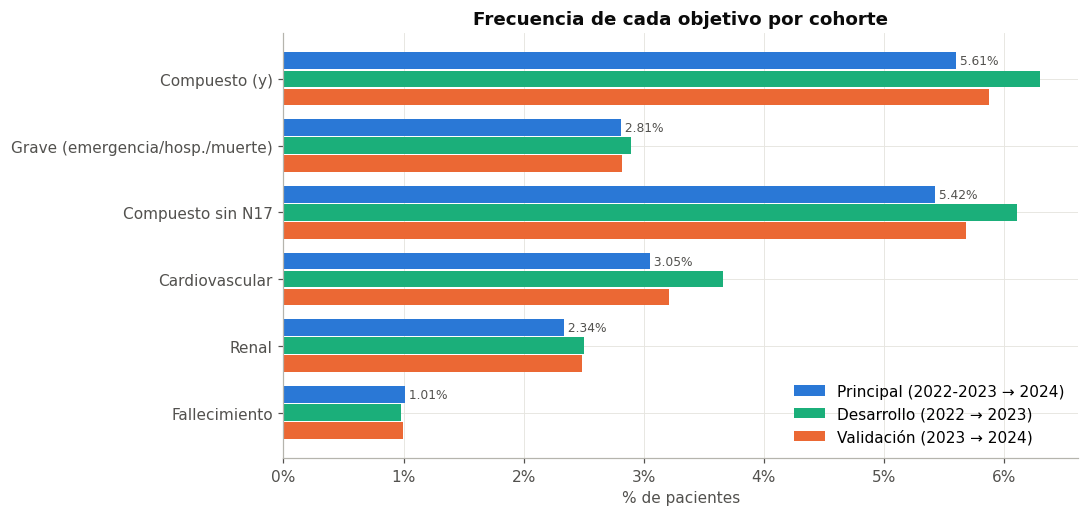

,Principal (2022-2023 → 2024),Desarrollo (2022 → 2023),Validación (2023 → 2024)
Compuesto (y),5.61,6.30,5.88
Grave (emergencia/hosp./muerte),2.81,2.90,2.82
Compuesto sin N17,5.42,6.11,5.68
Cardiovascular,3.05,3.66,3.21
Renal,2.34,2.51,2.49
Fallecimiento,1.01,0.98,0.99


,Pacientes,Con y = 1,También en la cohorte de desarrollo
Principal,419226,23498,59.4%
Desarrollo,303975,19157,—
Validación,334894,19676,55.8%


In [4]:
NOMBRES_OBJ = {'y': 'Compuesto (y)', 'y_grave': 'Grave (emergencia/hosp./muerte)', 'y_sin_n17': 'Compuesto sin N17',
               'y_cardiovascular': 'Cardiovascular', 'y_erc': 'Renal', 'y_fallecido': 'Fallecimiento',
               'y_acv': 'ACV / AIT', 'y_iam': 'Infarto', 'y_ic': 'Insuf. cardíaca'}
prevalencias = pd.DataFrame({
    'Principal (2022-2023 → 2024)': objetivos.mean(),
    'Desarrollo (2022 → 2023)': desarrollo[OBJETIVOS].mean(),
    'Validación (2023 → 2024)': validacion[OBJETIVOS].mean(),
}).loc[list(NOMBRES_OBJ)[:6]] * 100

fig, ax = plt.subplots(figsize=(10, 4.8))
pos = np.arange(len(prevalencias))[::-1]
for k, (col, color) in enumerate(zip(prevalencias.columns, [AZUL, AQUA, NARANJA])):
    ax.barh(pos + (1 - k) * 0.27, prevalencias[col], height=0.25, color=color, label=col)
for p, v in zip(pos, prevalencias.iloc[:, 0]):
    ax.text(v, p + 0.27, f' {v:.2f}%', va='center', fontsize=8, color=TEXTO_2)
ax.set_yticks(pos, [NOMBRES_OBJ[i] for i in prevalencias.index])
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set(title='Frecuencia de cada objetivo por cohorte', xlabel='% de pacientes')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

conteos = pd.DataFrame({c: [len(d), int(d['y'].sum())] for c, d in
                        [('Principal', objetivos), ('Desarrollo', desarrollo), ('Validación', validacion)]},
                       index=['Pacientes', 'Con y = 1']).T
conteos['También en la cohorte de desarrollo'] = [f"{objetivos.index.isin(desarrollo.index).mean():.1%}", '—',
                                                  f"{validacion.index.isin(desarrollo.index).mean():.1%}"]
display(prevalencias.rename(index=NOMBRES_OBJ).round(2))
conteos

## 3. Datos para modelar

Se usa **la misma partición de `03_random_forest.ipynb`** (80/20 estratificada, semilla 42, sin `dias_hosp` ni `pad_media`), así los resultados son comparables con los cuadernos anteriores. Los objetivos alternativos se agregan por paciente, sin cambiar el orden de las filas.

Todos los modelos de este cuaderno se entrenan **sin pesos de clase**: la curva de decisión y la validación de la calibración necesitan probabilidades bien calibradas (cuadernos 02 y 03).

In [5]:
df = pd.read_csv(RUTA_DATASET, index_col='paciente')
COLS_ELIMINAR = [c for c in ['dias_hosp', 'pad_media'] if c in df.columns]
y = df['y']
X = df.drop(columns=['y'] + COLS_ELIMINAR)
VARIABLES = list(X.columns)

objetivos.index = objetivos.index.astype(df.index.dtype)
assert set(objetivos.index) == set(df.index), \
    "objetivos_alternativos.csv no corresponde a este dataset_consolidado.csv: usa RECONSTRUIR_COHORTES = True"
objetivos = objetivos.loc[df.index]
dif_y = (objetivos['y'] != y).mean()
assert dif_y < 0.02, "objetivos_alternativos.csv no corresponde a este dataset_consolidado.csv: usa RECONSTRUIR_COHORTES = True"
if dif_y > 0:
    print(f"Nota: y de dataset_consolidado.csv y el y de un año (2024) difieren en {dif_y:.2%} de los pacientes "
          "(ver la sección 2). Los modelos se entrenan con el y de dataset_consolidado.csv, igual que en 02 y 03.")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
obj_train, obj_test = objetivos.loc[X_train.index], objetivos.loc[X_test.index]
print(f"Train: {len(X_train):,} | Test: {len(X_test):,} | Variables: {len(VARIABLES)}")

def nuevo_rf():
    return Pipeline([('imputer', SimpleImputer(strategy='median')),
                     ('rf', RandomForestClassifier(n_estimators=N_ARBOLES, n_jobs=-1, random_state=SEED, **PARAMS_RF))])

def nueva_rl():
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                     ('modelo', LogisticRegression(C=C_RL, max_iter=2000, random_state=SEED))])

def metricas(y_true, prob):
    y_true = np.asarray(y_true)
    top = np.argsort(-prob)[:int(len(prob) * 0.10)]
    return {'ROC-AUC': roc_auc_score(y_true, prob), 'PR-AUC': average_precision_score(y_true, prob),
            'Brier': brier_score_loss(y_true, prob), 'Captura top 10% (%)': y_true[top].sum() / y_true.sum() * 100,
            'Prevalencia (%)': y_true.mean() * 100}

def bootstrap_auc(y_true, probs, n=N_BOOT, seed=SEED):
    # Bootstrap PAREADO: los mismos pacientes remuestreados para todos los modelos
    y_true = np.asarray(y_true)
    rng = np.random.default_rng(seed)
    filas = []
    for _ in range(n):
        b = rng.integers(0, len(y_true), len(y_true))
        if y_true[b].min() == y_true[b].max():
            continue
        filas.append({k: roc_auc_score(y_true[b], p[b]) for k, p in probs.items()})
    return pd.DataFrame(filas)

def ic95(serie):
    return f"{serie.mean():.4f} [{serie.quantile(0.025):.4f}; {serie.quantile(0.975):.4f}]"

Nota: y de dataset_consolidado.csv y el y de un año (2024) difieren en 0.00% de los pacientes (ver la sección 2). Los modelos se entrenan con el y de dataset_consolidado.csv, igual que en 02 y 03.
Train: 335,380 | Test: 83,846 | Variables: 34


## 4. Modelos de referencia

Un revisor preguntará cuánto aportan las 34 variables frente a lo que un médico conoce de un vistazo. Se comparan cuatro modelos en el mismo test:

| Modelo | Variables |
|---|---|
| Solo edad y sexo | `edad`, `masculino` |
| Clínico mínimo | Edad, sexo, las 5 comorbilidades, `hta_cardiaca`, `pas_media` y `sin_medicion_pa`: lo que figura en una historia clínica básica |
| Regresión logística completa | Las 34 variables |
| Random Forest | Las 34 variables, con los hiperparámetros de 03 |

Las dos referencias son regresiones logísticas: así la comparación mide el aporte de **la información**, no del algoritmo.

In [6]:
t0 = time.time()
REFERENCIAS = {
    'Solo edad y sexo': ['edad', 'masculino'],
    'Clínico mínimo': ['edad', 'masculino', 'diabetes', 'dislipidemia', 'obesidad', 'fib_auricular', 'cardiopatia',
                       'hta_cardiaca', 'pas_media', 'sin_medicion_pa'],
}
prob_test = {}
for nombre, cols in REFERENCIAS.items():
    prob_test[nombre] = nueva_rl().fit(X_train[cols], y_train).predict_proba(X_test[cols])[:, 1]

rl_completa = nueva_rl().fit(X_train, y_train)
prob_test['Regresión logística completa'] = rl_completa.predict_proba(X_test)[:, 1]
rf_principal = nuevo_rf().fit(X_train, y_train)
prob_test['Random Forest'] = rf_principal.predict_proba(X_test)[:, 1]
print("Tiempo:", cronometro(t0))

tabla_referencia = pd.DataFrame({k: metricas(y_test, p) for k, p in prob_test.items()}).T.drop(columns='Prevalencia (%)')
tabla_referencia.insert(0, 'Variables', [len(c) for c in REFERENCIAS.values()] + [len(VARIABLES)] * 2)
tabla_referencia.round(4)

Tiempo: 0.3 min


,Variables,ROC-AUC,PR-AUC,Brier,Captura top 10% (%)
Solo edad y sexo,2,0.5943,0.0756,0.0526,14.9819
Clínico mínimo,10,0.6489,0.1000,0.0520,21.3024
Regresión logística completa,34,0.6918,0.1177,0.0515,24.7712
Random Forest,34,0.7043,0.1238,0.0512,26.0694


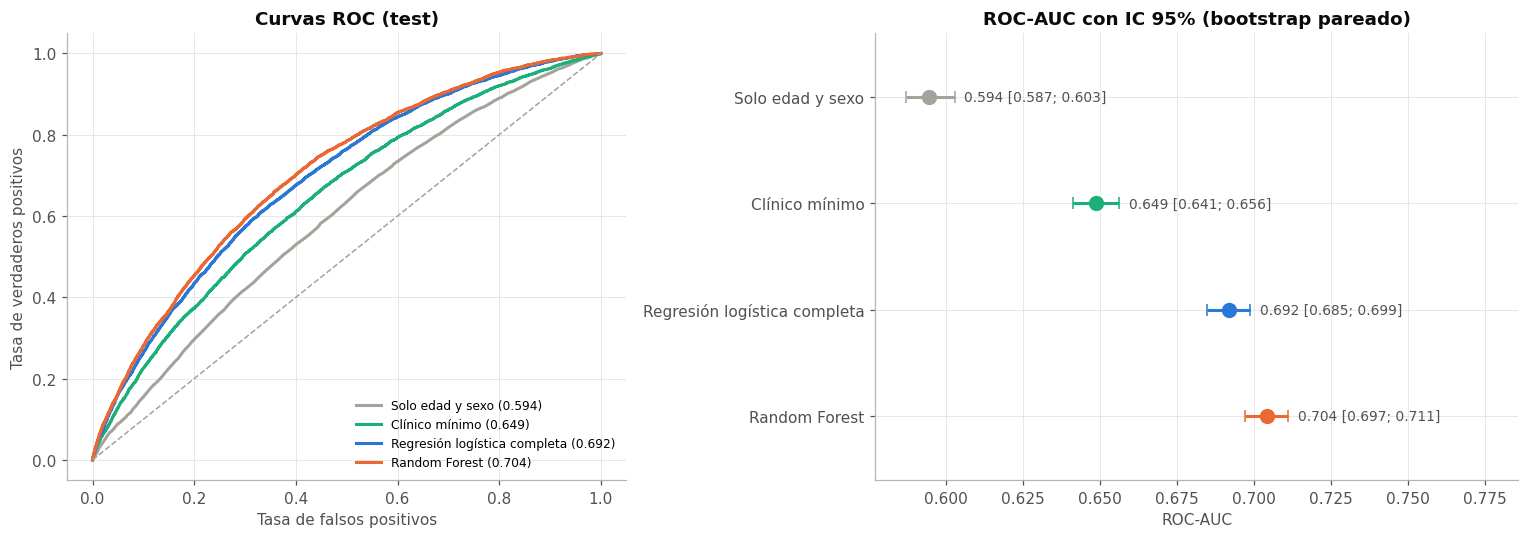

,Δ ROC-AUC [IC 95%],¿Significativa?
Comparación,,
Random Forest − Clínico mínimo,0.0553 [0.0479; 0.0622],Sí
Regresión logística completa − Clínico mínimo,0.0429 [0.0376; 0.0483],Sí
Clínico mínimo − Solo edad y sexo,0.0544 [0.0475; 0.0606],Sí
Random Forest − Regresión logística completa,0.0124 [0.0084; 0.0164],Sí


In [7]:
boot_ref = bootstrap_auc(y_test, prob_test)
comparaciones = [('Random Forest', 'Clínico mínimo'), ('Regresión logística completa', 'Clínico mínimo'),
                 ('Clínico mínimo', 'Solo edad y sexo'), ('Random Forest', 'Regresión logística completa')]
tabla_delta = pd.DataFrame([{'Comparación': f'{a} − {b}', 'Δ ROC-AUC [IC 95%]': ic95(boot_ref[a] - boot_ref[b]),
                             '¿Significativa?': 'Sí' if ((boot_ref[a] - boot_ref[b]).quantile(0.025) > 0) else 'No'}
                            for a, b in comparaciones]).set_index('Comparación')

COLORES = {'Solo edad y sexo': GRIS, 'Clínico mínimo': AQUA, 'Regresión logística completa': AZUL, 'Random Forest': NARANJA}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1, 1.15]})
for nombre, p in prob_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=COLORES[nombre], linewidth=2, label=f"{nombre} ({roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=GRIS, linestyle='--', linewidth=1)
axes[0].set(title='Curvas ROC (test)', xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos')
axes[0].legend(loc='lower right', fontsize=8)

orden = list(prob_test)
pos = np.arange(len(orden))[::-1]
for p_, k in zip(pos, orden):
    m, lo, hi = boot_ref[k].mean(), boot_ref[k].quantile(0.025), boot_ref[k].quantile(0.975)
    axes[1].errorbar(m, p_, xerr=[[m - lo], [hi - m]], fmt='o', color=COLORES[k], ecolor=COLORES[k],
                     elinewidth=2, capsize=4, markersize=9)
    axes[1].text(hi + 0.003, p_, f'{m:.3f} [{lo:.3f}; {hi:.3f}]', va='center', fontsize=9, color=TEXTO_2)
lo_min = min(boot_ref[k].quantile(0.025) for k in orden)
hi_max = max(boot_ref[k].quantile(0.975) for k in orden)
axes[1].set_xlim(lo_min - 0.01, hi_max + (hi_max - lo_min) * 0.6)
axes[1].set_yticks(pos, orden)
axes[1].set_ylim(-0.6, len(orden) - 0.4)
axes[1].set(title='ROC-AUC con IC 95% (bootstrap pareado)', xlabel='ROC-AUC')
plt.tight_layout()
plt.show()
tabla_delta

**Interpretación.** Las variables administrativas aportan información propia, y más de lo esperado.

- **Edad y sexo** solos llegan a 0.594: apenas mejor que el azar. El 10% de mayor riesgo concentra el 15.0% de las complicaciones.
- **El modelo clínico mínimo** (edad, sexo, comorbilidades y presión: lo que figura en una historia básica) sube a **0.649**.
- **Las 34 variables** llevan la regresión logística a 0.692 y el Random Forest a **0.704**.

El salto del clínico mínimo al Random Forest (**+0.055**, IC 95%: 0.048-0.062) es **tan grande como el de edad y sexo al clínico mínimo** (+0.054). Es decir, el historial de uso del sistema, los consumos y la ubicación pesan tanto como las comorbilidades. En la práctica, el top 10% del Random Forest captura el 26.1% de las complicaciones, frente al 21.3% del clínico mínimo: casi **5 de cada 100 complicaciones más** con la misma capacidad de seguimiento.

La **hipótesis 1 se refuta**: el clínico mínimo no se acerca al modelo completo (0.649, por debajo del rango esperado de 0.66-0.68). La diferencia entre Random Forest y regresión logística (+0.012, significativa) indica además que parte de la señal está en interacciones o relaciones no lineales que la regresión no capta.

## 5. Curva de decisión (beneficio neto)

El ROC-AUC dice si el modelo **ordena** bien a los pacientes, pero no si conviene **usarlo**. La curva de decisión (Vickers y Elkin, 2006) responde a esa pregunta. Para cada umbral de probabilidad $p_t$ a partir del cual se haría seguimiento a un paciente, calcula:

$$\text{Beneficio neto} = \frac{VP}{n} - \frac{FP}{n} \cdot \frac{p_t}{1 - p_t}$$

El factor $p_t / (1 - p_t)$ expresa cuánto "cuesta" un falso positivo en relación con el beneficio de un verdadero positivo. Por ejemplo, $p_t$ = 10% significa estar dispuesto a seguir a 9 pacientes sin evento para captar 1 con evento. El modelo es útil en los umbrales donde su curva supera a las dos estrategias por defecto: **seguir a todos** y **no seguir a nadie** (beneficio 0).

Para un seguimiento de bajo costo (una llamada, adelantar un control) el rango razonable es aproximadamente **3%-15%**. Como el beneficio neto usa la probabilidad, **solo tiene sentido con modelos calibrados**: por eso aquí no se usan pesos de clase.

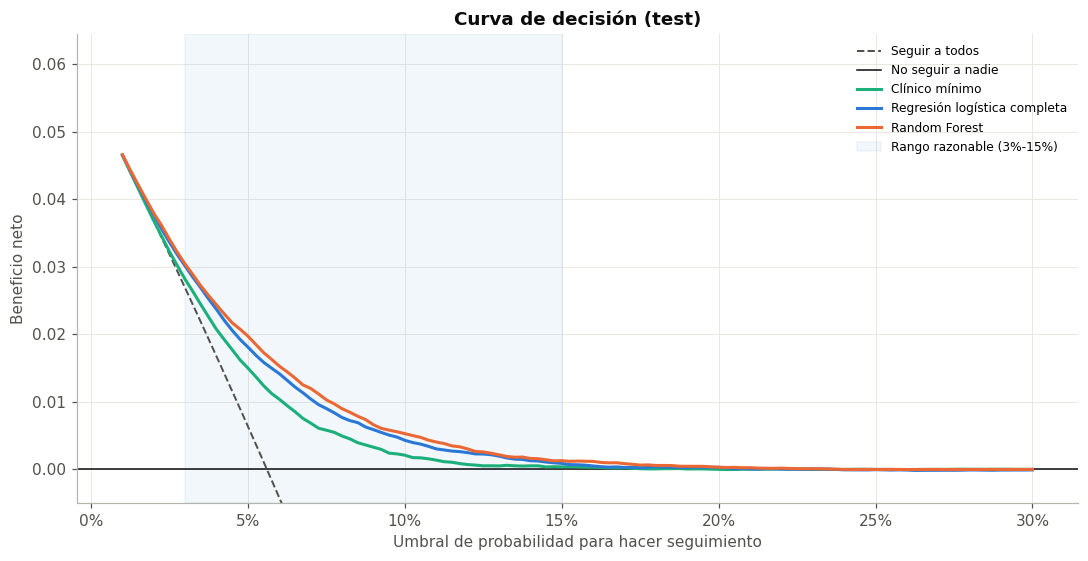

Beneficio neto  \
Umbral Modelo                                         
3%     Clínico mínimo                        0.0281   
       Regresión logística completa          0.0301   
       Random Forest                         0.0304   
5%     Clínico mínimo                        0.0150   
       Regresión logística completa          0.0181   
       Random Forest                         0.0197   
8%     Clínico mínimo                        0.0049   
       Regresión logística completa          0.0077   
       Random Forest                         0.0090   
10%    Clínico mínimo                        0.0021   
       Regresión logística completa          0.0043   
       Random Forest                         0.0053   
15%    Clínico mínimo                        0.0004   
       Regresión logística completa          0.0009   
       Random Forest                         0.0013   
20%    Clínico mínimo                        0.0000   
       Regresión logística completa          0.0003   
       Random Forest                         0.0003   

                                     Mejor estrategia por defecto  \
Umbral Modelo                                                       
3%     Clínico mínimo                                      0.0268   
       Regresión logística completa                        0.0268   
       Random Forest                                       0.0268   
5%     Clínico mínimo                                      0.0064   
       Regresión logística completa                        0.0064   
       Random Forest                                       0.0064   
8%     Clínico mínimo                                      0.0000   
       Regresión logística completa                        0.0000   
       Random Forest                                       0.0000   
10%    Clínico mínimo                                      0.0000   
       Regresión logística completa                        0.0000   
       Random Forest                                       0.0000   
15%    Clínico mínimo                                      0.0000   
       Regresión logística completa                        0.0000   
       Random Forest                                       0.0000   
20%    Clínico mínimo                                      0.0000   
       Regresión logística completa                        0.0000   
       Random Forest                                       0.0000   

                                     Seguimientos innecesarios evitados por 100 pacientes  \
Umbral Modelo                                                                               
3%     Clínico mínimo                                                           4.1405      
       Regresión logística completa                                            10.5074      
       Random Forest                                                           11.4404      
5%     Clínico mínimo                                                          16.4134      
       Regresión logística completa                                            22.3171      
       Random Forest                                                           25.4061      
8%     Clínico mínimo                                                          35.6248      
       Regresión logística completa                                            38.7896      
       Random Forest                                                           40.2816      
10%    Clínico mínimo                                                          45.8555      
       Regresión logística completa                                            47.8353      
       Random Forest                                                           48.7227      
15%    Clínico mínimo                                                          62.8537      
       Regresión logística completa                                            63.1439      
       Random Forest                                               

In [8]:
def beneficio_neto(y_true, prob, umbrales):
    y_true = np.asarray(y_true)
    n = len(y_true)
    nb = []
    for pt in umbrales:
        marcados = prob >= pt
        vp = (marcados & (y_true == 1)).sum()
        fp = (marcados & (y_true == 0)).sum()
        nb.append(vp / n - fp / n * pt / (1 - pt))
    return np.array(nb)

UMBRALES = np.round(np.arange(0.01, 0.301, 0.0025), 4)
prev = y_test.mean()
curvas_dca = pd.DataFrame({'Umbral': UMBRALES, 'Seguir a todos': prev - (1 - prev) * UMBRALES / (1 - UMBRALES)})
for nombre in ['Clínico mínimo', 'Regresión logística completa', 'Random Forest']:
    curvas_dca[nombre] = beneficio_neto(y_test, prob_test[nombre], UMBRALES)

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(UMBRALES, curvas_dca['Seguir a todos'], color=TEXTO_2, linestyle='--', linewidth=1.3, label='Seguir a todos')
ax.axhline(0, color=TEXTO, linewidth=1, label='No seguir a nadie')
for nombre in ['Clínico mínimo', 'Regresión logística completa', 'Random Forest']:
    ax.plot(UMBRALES, curvas_dca[nombre], color=COLORES[nombre], linewidth=2, label=nombre)
ax.axvspan(0.03, 0.15, color=AZUL, alpha=0.06, label='Rango razonable (3%-15%)')
ax.set_ylim(-0.005, prev * 1.15)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(title='Curva de decisión (test)', xlabel='Umbral de probabilidad para hacer seguimiento',
       ylabel='Beneficio neto')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

PUNTOS = [0.03, 0.05, 0.08, 0.10, 0.15, 0.20]
filas = []
for pt in PUNTOS:
    fila = curvas_dca.iloc[np.argmin(np.abs(curvas_dca['Umbral'] - pt))]
    for nombre in ['Clínico mínimo', 'Regresión logística completa', 'Random Forest']:
        mejora = fila[nombre] - max(fila['Seguir a todos'], 0)
        filas.append({'Umbral': f'{pt:.0%}', 'Modelo': nombre, 'Beneficio neto': fila[nombre],
                      'Mejor estrategia por defecto': max(fila['Seguir a todos'], 0),
                      'Seguimientos innecesarios evitados por 100 pacientes': (fila[nombre] - fila['Seguir a todos']) / (pt / (1 - pt)) * 100,
                      '% marcados': (prob_test[nombre] >= pt).mean() * 100})
tabla_dca = pd.DataFrame(filas).set_index(['Umbral', 'Modelo'])
tabla_dca.round(4)

**Interpretación.** El modelo es útil para decidir, no solo para ordenar, y la **hipótesis 2 se confirma**: el Random Forest da más beneficio neto que "seguir a todos" y que "no seguir a nadie" en **todos** los umbrales entre 3% y 15%.

- **Umbral de 5%** (seguir a quien tenga al menos 1 en 20 de complicarse): el beneficio neto del Random Forest es 0.0197, **tres veces** el de seguir a todos (0.0064). Equivale a **evitar 25 seguimientos innecesarios por cada 100 pacientes**, marcando al 46% de la cohorte.
- **Umbral de 10%**: marca al 13.5% de los pacientes y evita 49 seguimientos innecesarios por cada 100. Aquí "seguir a todos" ya da beneficio negativo.
- **Por encima de 15-20%** el beneficio neto se acerca a cero: muy pocos pacientes superan ese riesgo.

En todos los umbrales el orden es el mismo: Random Forest > regresión logística > clínico mínimo. **Conclusión práctica:** el modelo sirve para **priorizar acciones de bajo costo** (una llamada, adelantar un control, revisar la adherencia), que se justifican con riesgos bajos o moderados. No sirve para intervenciones costosas o riesgosas, que exigirían identificar pacientes con un riesgo individual alto.

## 6. Objetivos alternativos: ¿predice complicaciones o uso del sistema?

En los cuadernos anteriores, `prop_capita`, `nivel_eess_max` y `n_atenciones` estuvieron entre las variables más importantes. Eso tiene dos lecturas posibles: (a) son marcadores reales de gravedad (al paciente más complejo se lo deriva a hospitales), o (b) **sesgo de detección**: a quien va más se le registran más diagnósticos, incluido el evento. Este análisis distingue entre ambas de tres maneras:

1. **6.1** El modelo entrenado con `y`, evaluado contra cada objetivo alternativo, sin reentrenar.
2. **6.2** Un modelo reentrenado para cada objetivo.
3. **6.3** Los coeficientes de la regresión logística para `y`, `y_grave` y `y_erc`.

### 6.1 El modelo de `y` frente a cada objetivo

In [9]:
filas = []
for o in OBJETIVOS:
    yo = obj_test[o]
    if yo.sum() < 10:
        continue
    fila = {'Objetivo': NOMBRES_OBJ[o], 'Casos en test': int(yo.sum()), 'Prevalencia (%)': yo.mean() * 100}
    fila['ROC-AUC RL'] = roc_auc_score(yo, prob_test['Regresión logística completa'])
    fila['ROC-AUC RF'] = roc_auc_score(yo, prob_test['Random Forest'])
    filas.append(fila)
tabla_sin_reentrenar = pd.DataFrame(filas).set_index('Objetivo')

# Composición: ¿qué parte de los y = 1 son eventos graves?
y1 = obj_test[obj_test['y'] == 1]
print(f"De los {len(y1):,} pacientes con y = 1 en test, {y1['y_grave'].mean():.1%} tienen un evento grave "
      f"(emergencia, hospitalización o muerte) y {1 - y1['y_sin_n17'].mean():.1%} solo tienen N17.")
tabla_sin_reentrenar.round(4)

De los 4,700 pacientes con y = 1 en test, 50.4% tienen un evento grave (emergencia, hospitalización o muerte) y 3.4% solo tienen N17.


,Casos en test,Prevalencia (%),ROC-AUC RL,ROC-AUC RF
Objetivo,,,,
Compuesto (y),4700,5.6055,0.6918,0.7042
Grave (emergencia/hosp./muerte),2368,2.8242,0.6921,0.7061
Compuesto sin N17,4540,5.4147,0.6943,0.7062
Cardiovascular,2575,3.0711,0.6816,0.6860
Renal,1971,2.3507,0.6820,0.7046
Fallecimiento,868,1.0352,0.7284,0.7401
ACV / AIT,1124,1.3406,0.6766,0.6774
Infarto,206,0.2457,0.6637,0.6727
Insuf. cardíaca,1395,1.6638,0.6876,0.6940


### 6.2 Un modelo para cada objetivo
Se entrenan la regresión logística y el Random Forest con cada objetivo, usando la misma partición y las mismas variables. Los intervalos son bootstrap de 95%.

y: listo (0.1 min)
y_grave: listo (0.6 min)
y_sin_n17: listo (1.1 min)
y_cardiovascular: listo (1.5 min)
y_erc: listo (2.0 min)
y_fallecido: listo (2.4 min)


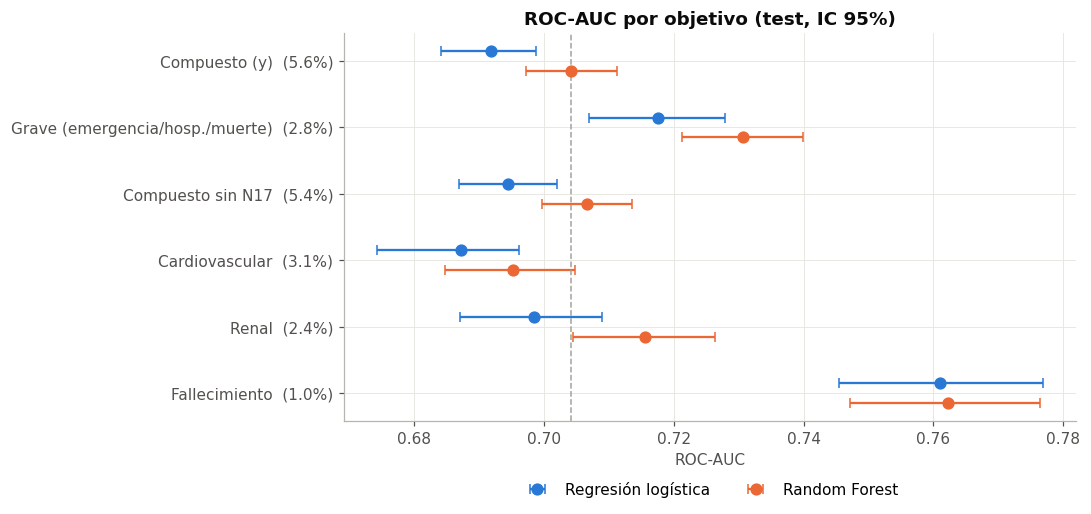

ROC-AUC  PR-AUC   Brier  \
Objetivo                        Modelo                            
Compuesto (y)                   RL       0.6918  0.1177  0.0515   
                                RF       0.7042  0.1238  0.0512   
Grave (emergencia/hosp./muerte) RL       0.7176  0.0760  0.0269   
                                RF       0.7307  0.0822  0.0268   
Compuesto sin N17               RL       0.6944  0.1157  0.0499   
                                RF       0.7066  0.1214  0.0496   
Cardiovascular                  RL       0.6872  0.0689  0.0293   
                                RF       0.6953  0.0732  0.0292   
Renal                           RL       0.6984  0.0525  0.0227   
                                RF       0.7156  0.0601  0.0226   
Fallecimiento                   RL       0.7610  0.0417  0.0101   
                                RF       0.7622  0.0440  0.0101   

                                        Captura top 10% (%)  Prevalencia (%)  \
Objetivo                        Modelo                                         
Compuesto (y)                   RL                  24.7660           5.6055   
                                RF                  26.0638           5.6055   
Grave (emergencia/hosp./muerte) RL                  29.6453           2.8242   
                                RF                  31.4189           2.8242   
Compuesto sin N17               RL                  25.1322           5.4147   
                                RF                  26.0573           5.4147   
Cardiovascular                  RL                  25.7864           3.0711   
                                RF                  27.3010           3.0711   
Renal                           RL                  26.2303           2.3507   
                                RF                  28.7671           2.3507   
Fallecimiento                   RL                  38.3641           1.0352   
                                RF                  39.0553           1.0352   

                                        IC inf  IC sup  
Objetivo                        Modelo                  
Compuesto (y)                   RL      0.6841  0.6988  
                                RF      0.6972  0.7112  
Grave (emergencia/hosp./muerte) RL      0.7069  0.7280  
                                RF      0.7212  0.7400  
Compuesto sin N17               RL      0.6868  0.7020  
                                RF      0.6997  0.7136  
Cardiovascular                  RL      0.6743  0.6961  
                                RF      0.6847  0.7048  
Renal                           RL      0.6871  0.7090  
                                RF      0.7045  0.7263  
Fallecimiento                   RL      0.7455  0.7769  
                                RF      0.7472  0.7764

In [10]:
t0 = time.time()
resultados_obj, prob_obj = [], {}
for o in ['y'] + OBJETIVOS_REENTRENAR:
    yo_tr, yo_te = obj_train[o], obj_test[o]
    if yo_tr.sum() < 50 or yo_te.sum() < 10:
        print(f"{o}: muy pocos casos, se omite")
        continue
    if o == 'y':
        p = {'RL': prob_test['Regresión logística completa'], 'RF': prob_test['Random Forest']}
    else:
        p = {'RL': nueva_rl().fit(X_train, yo_tr).predict_proba(X_test)[:, 1],
             'RF': nuevo_rf().fit(X_train, yo_tr).predict_proba(X_test)[:, 1]}
    prob_obj[o] = p
    b = bootstrap_auc(yo_te, p, n=max(N_BOOT // 2, 100))
    for m, pm in p.items():
        resultados_obj.append({'Objetivo': NOMBRES_OBJ[o], 'Modelo': m, **metricas(yo_te, pm),
                               'IC inf': b[m].quantile(0.025), 'IC sup': b[m].quantile(0.975)})
    print(f"{o}: listo ({cronometro(t0)})")
tabla_obj = pd.DataFrame(resultados_obj).set_index(['Objetivo', 'Modelo'])

fig, ax = plt.subplots(figsize=(10, 4.8))
nombres = tabla_obj.index.get_level_values(0).unique()
pos = np.arange(len(nombres))[::-1]
for desplaz, m, color in [(0.15, 'RL', AZUL), (-0.15, 'RF', NARANJA)]:
    t = tabla_obj.xs(m, level='Modelo').loc[nombres]
    ax.errorbar(t['ROC-AUC'], pos + desplaz, xerr=[t['ROC-AUC'] - t['IC inf'], t['IC sup'] - t['ROC-AUC']],
                fmt='o', color=color, ecolor=color, elinewidth=1.5, capsize=3, markersize=7,
                label='Regresión logística' if m == 'RL' else 'Random Forest')
ref_auc = tabla_obj.loc[(NOMBRES_OBJ['y'], 'RF'), 'ROC-AUC']
ax.axvline(ref_auc, color=GRIS, linestyle='--', linewidth=1)
ax.set_yticks(pos, [f"{n}  ({tabla_obj.loc[(n, 'RF'), 'Prevalencia (%)']:.1f}%)" for n in nombres])
ax.set(title='ROC-AUC por objetivo (test, IC 95%)', xlabel='ROC-AUC')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()
tabla_obj.round(4)

### 6.3 ¿Cambia lo que el modelo aprende?
Coeficientes estandarizados de la regresión logística: cuánto cambia el log-odds por cada desviación estándar de la variable. Si las variables de uso del sistema pierden peso al pasar de `y` a `y_grave`, eso es evidencia de que parte de su importancia venía del sesgo de detección.

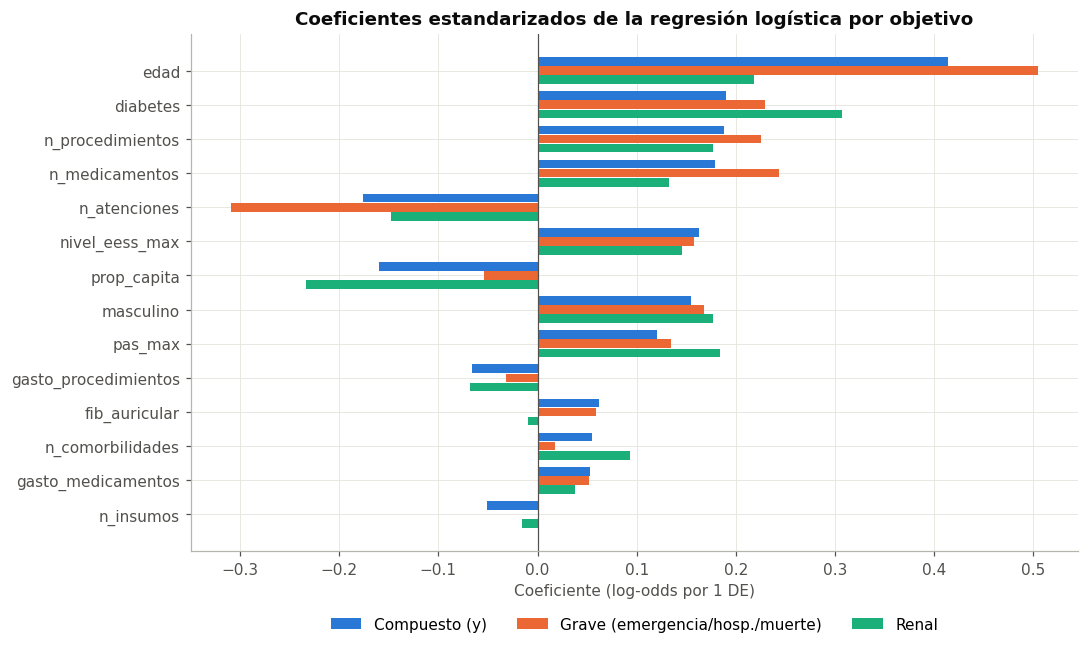

Variables de uso del sistema (coeficientes):


,Compuesto (y),Grave (emergencia/hosp./muerte),Renal
prop_capita,-0.160,-0.054,-0.233
nivel_eess_max,0.163,0.157,0.146
n_atenciones,-0.176,-0.309,-0.148
n_procedimientos,0.188,0.225,0.177
n_diagnosticos,0.016,-0.113,0.083
n_mediciones_pa,-0.002,-0.075,0.019
dias_desde_ultima,0.015,0.096,-0.038


In [11]:
coef = {}
for o in ['y', 'y_grave', 'y_erc']:
    if o not in prob_obj:
        continue
    m = rl_completa if o == 'y' else nueva_rl().fit(X_train, obj_train[o])
    coef[NOMBRES_OBJ[o]] = pd.Series(m.named_steps['modelo'].coef_[0], index=VARIABLES)
coef = pd.DataFrame(coef)
top = coef.iloc[:, 0].abs().sort_values(ascending=False).head(14).index
coef_top = coef.loc[top]

fig, ax = plt.subplots(figsize=(10, 6))
pos = np.arange(len(coef_top))[::-1]
alto = 0.8 / coef_top.shape[1]
for k, (col, color) in enumerate(zip(coef_top.columns, [AZUL, NARANJA, AQUA])):
    ax.barh(pos + (coef_top.shape[1] / 2 - k - 0.5) * alto, coef_top[col], height=alto * 0.95, color=color, label=col)
ax.axvline(0, color=TEXTO_2, linewidth=0.8)
ax.set_yticks(pos, coef_top.index)
ax.set(title='Coeficientes estandarizados de la regresión logística por objetivo', xlabel='Coeficiente (log-odds por 1 DE)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout()
plt.show()

USO = ['prop_capita', 'nivel_eess_max', 'n_atenciones', 'n_procedimientos', 'n_diagnosticos', 'n_mediciones_pa', 'dias_desde_ultima']
print("Variables de uso del sistema (coeficientes):")
coef.loc[[c for c in USO if c in coef.index]].round(3)

**Interpretación.** El modelo predice complicaciones, no solo uso del sistema, aunque una parte de la señal sí es sesgo de detección. La **hipótesis 3 se confirma en lo principal**.

**1. La discriminación mejora con los eventos graves.** La mitad de los casos (50.4%) son graves: se registraron en emergencia u hospitalización, o terminaron en fallecimiento. Reentrenado para ese objetivo, el Random Forest sube de 0.704 a **0.731**, y con el fallecimiento llega a **0.762**. Si el modelo solo midiera quién va más a controles, debería empeorar con eventos que se detectan igual vaya o no el paciente a sus controles, y pasa lo contrario.

**2. La lesión renal aguda no distorsiona el objetivo.** Solo el 3.4% de los casos se deben únicamente a N17; sin ellos, el AUC apenas cambia (0.707).

**3. Los coeficientes muestran dónde está el sesgo:**

| Variable | Compuesto | Grave | Renal | Lectura |
|---|---|---|---|---|
| `prop_capita` | −0.160 | **−0.054** | **−0.233** | Pierde dos tercios de su peso con el evento grave y gana peso con el renal: **huella del sesgo de detección**. La enfermedad renal se diagnostica, o no, según el tipo de atención que recibe el paciente |
| `nivel_eess_max` | 0.163 | 0.157 | 0.146 | Estable en los tres objetivos: probablemente marca **gravedad real** (al paciente complicado se lo deriva a establecimientos de mayor nivel) |
| `n_atenciones` | −0.176 | **−0.309** | −0.148 | Más protectora frente al evento grave |
| `dias_desde_ultima` | 0.015 | **+0.096** | −0.038 | Pasa a ser de riesgo con el evento grave |

Las dos últimas filas cuentan una historia coherente: **a igualdad de lo demás, el paciente con seguimiento continuo tiene menos eventos graves, y el que lleva más tiempo sin atenderse, más**. Es un hallazgo con lectura de salud pública. La hipótesis esperaba que `n_atenciones` se acercara a cero; en cambio se volvió más protectora, lo que sugiere un efecto real de la continuidad de la atención y no un artefacto de registro (aunque, al ser observacional, no prueba causalidad).

**4. Hay un límite claro.** Los eventos cardiovasculares agudos son los menos predecibles: ACV/AIT 0.677 e infarto 0.673 con el modelo de `y`, y 0.695 el objetivo cardiovascular reentrenado. Dependen de factores que no están en los datos: tabaquismo, colesterol, control real de la presión y adherencia al tratamiento.

## 7. Validación temporal

Hasta ahora, train y test vienen del mismo periodo. En la práctica, un modelo se entrena con datos de un año y se usa con pacientes del año siguiente. En ese tiempo cambia el volumen de atenciones (≈450 mil al mes en 2022 frente a ≈800 mil en 2024, según el EDA), la cobertura del SIS y la forma de registrar. La validación temporal mide cuánto se degrada el modelo por esos cambios.

```
Desarrollo:  |-- 2022 (X) --|-- 2023 (y) --|                    → entrenar (80%) y validación interna (20%)
Validación:                 |-- 2023 (X) --|-- 2024 (y) --|     → validación temporal
```

- Ambas cohortes usan **un año** de observación, así que su ROC-AUC no es directamente comparable con el 0.705 de la cohorte principal, que tiene dos años. Lo que importa es la comparación **interna frente a temporal** con el mismo diseño.
- Muchos pacientes están en las dos cohortes, un año después. Es lo habitual en validación temporal con registros administrativos, pero además se reporta el resultado **solo con pacientes nuevos** (los que no estaban en desarrollo).
- **Calibración.** Se reportan la razón observado/esperado (O/E: 1 = perfecta; > 1 significa que el modelo subestima el riesgo) y la pendiente de calibración (1 = perfecta; < 1 significa probabilidades demasiado extremas).

In [12]:
t0 = time.time()
X_d, y_d = desarrollo[VARIABLES], desarrollo['y']
X_v, y_v = validacion[VARIABLES], validacion['y']
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(X_d, y_d, test_size=0.2, random_state=SEED, stratify=y_d)
nuevos = ~X_v.index.isin(desarrollo.index)

def calibracion(y_true, prob):
    lp = np.log(np.clip(prob, 1e-6, 1 - 1e-6) / (1 - np.clip(prob, 1e-6, 1 - 1e-6)))
    m = LogisticRegression(C=1e6, max_iter=1000).fit(lp.reshape(-1, 1), y_true)
    return {'O/E': np.mean(y_true) / prob.mean(), 'Pendiente de calibración': m.coef_[0, 0]}

modelos_t = {'RL': nueva_rl().fit(Xd_tr, yd_tr), 'RF': nuevo_rf().fit(Xd_tr, yd_tr)}
print("Tiempo de entrenamiento:", cronometro(t0))

prob_t, filas = {}, []
conjuntos = [('Interna (desarrollo, 20%)', Xd_te, yd_te), ('Temporal (validación, todos)', X_v, y_v),
             ('Temporal (solo pacientes nuevos)', X_v[nuevos], y_v[nuevos])]
for m, modelo in modelos_t.items():
    for c, Xc, yc in conjuntos:
        p = modelo.predict_proba(Xc)[:, 1]
        prob_t[(m, c)] = (yc.to_numpy(), p)
        b = bootstrap_auc(yc, {'p': p}, n=max(N_BOOT // 2, 100))['p']
        filas.append({'Modelo': m, 'Conjunto': c, 'Pacientes': len(yc), **metricas(yc, p),
                      'IC inf': b.quantile(0.025), 'IC sup': b.quantile(0.975), **calibracion(yc, p)})
tabla_temporal = pd.DataFrame(filas).set_index(['Modelo', 'Conjunto'])
print(f"Pacientes de validación que también estaban en desarrollo: {(~nuevos).mean():.1%}")
tabla_temporal.round(4)

Tiempo de entrenamiento: 0.2 min
Pacientes de validación que también estaban en desarrollo: 55.8%


Pacientes  ROC-AUC  PR-AUC   Brier  \
Modelo Conjunto                                                               
RL     Interna (desarrollo, 20%)             60795   0.6992  0.1381  0.0571   
       Temporal (validación, todos)         334894   0.6875  0.1251  0.0538   
       Temporal (solo pacientes nuevos)     148110   0.7010  0.1284  0.0505   
RF     Interna (desarrollo, 20%)             60795   0.7070  0.1419  0.0569   
       Temporal (validación, todos)         334894   0.6955  0.1283  0.0536   
       Temporal (solo pacientes nuevos)     148110   0.7083  0.1308  0.0504   

                                         Captura top 10% (%)  Prevalencia (%)  \
Modelo Conjunto                                                                 
RL     Interna (desarrollo, 20%)                     25.6591           6.3015   
       Temporal (validación, todos)                  25.2744           5.8753   
       Temporal (solo pacientes nuevos)              26.7588           5.5182   
RF     Interna (desarrollo, 20%)                     27.0687           6.3015   
       Temporal (validación, todos)                  26.0724           5.8753   
       Temporal (solo pacientes nuevos)              27.5297           5.5182   

                                         IC inf  IC sup     O/E  \
Modelo Conjunto                                                   
RL     Interna (desarrollo, 20%)         0.6907  0.7075  0.9963   
       Temporal (validación, todos)      0.6836  0.6913  0.9167   
       Temporal (solo pacientes nuevos)  0.6950  0.7071  0.8988   
RF     Interna (desarrollo, 20%)         0.6986  0.7143  0.9977   
       Temporal (validación, todos)      0.6916  0.6991  0.9063   
       Temporal (solo pacientes nuevos)  0.7022  0.7139  0.8854   

                                         Pendiente de calibración  
Modelo Conjunto                                                    
RL     Interna (desarrollo, 20%)                           0.9858  
       Temporal (validación, todos)                        0.9526  
       Temporal (solo pacientes nuevos)                    1.0104  
RF     Interna (desarrollo, 20%)                           1.0566  
       Temporal (validación, todos)                        1.0057  
       Temporal (solo pacientes nuevos)                    1.0733

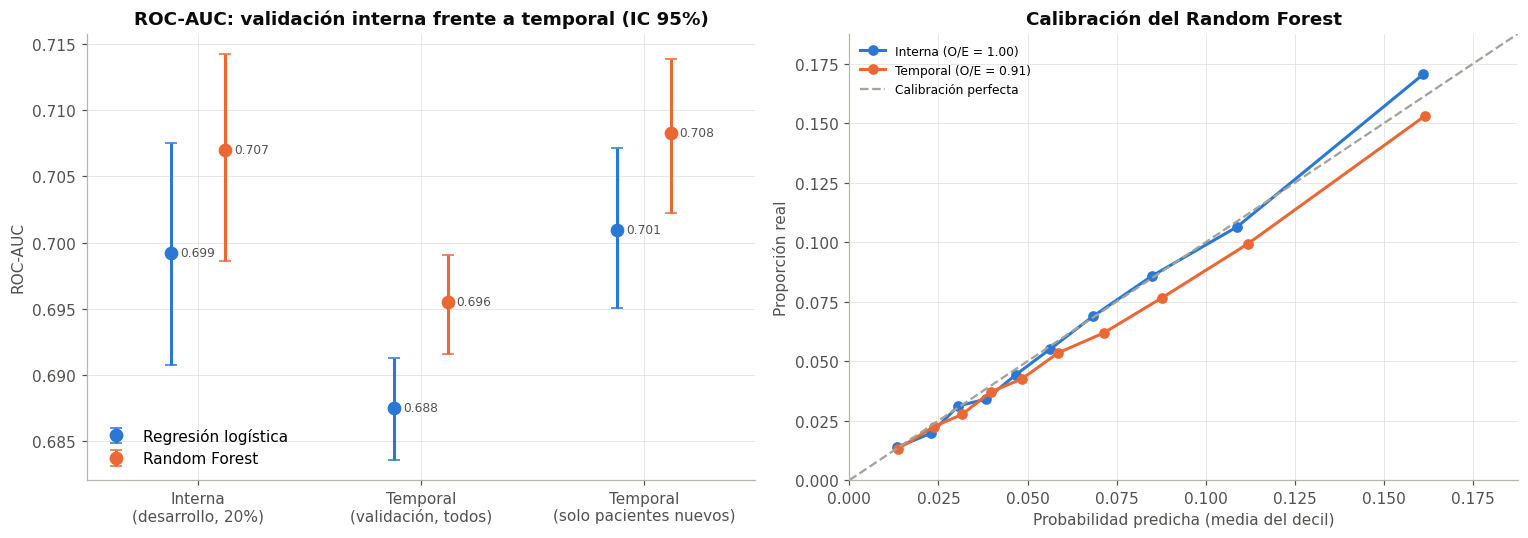

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
nombres_c = [c for c, _, _ in conjuntos]
x = np.arange(len(nombres_c))
for desplaz, m, color in [(-0.12, 'RL', AZUL), (0.12, 'RF', NARANJA)]:
    t = tabla_temporal.xs(m, level='Modelo').loc[nombres_c]
    axes[0].errorbar(x + desplaz, t['ROC-AUC'], yerr=[t['ROC-AUC'] - t['IC inf'], t['IC sup'] - t['ROC-AUC']],
                     fmt='o', color=color, ecolor=color, elinewidth=2, capsize=4, markersize=8,
                     label='Regresión logística' if m == 'RL' else 'Random Forest')
    for xi, v in zip(x + desplaz, t['ROC-AUC']):
        axes[0].text(xi + 0.04, v, f'{v:.3f}', va='center', fontsize=8, color=TEXTO_2)
axes[0].set_xticks(x, [c.replace(' (', '\n(') for c in nombres_c])
axes[0].set_xlim(-0.5, len(nombres_c) - 0.5)
axes[0].set(title='ROC-AUC: validación interna frente a temporal (IC 95%)', ylabel='ROC-AUC')
axes[0].legend(loc='lower left')

limite = 0
for c, color, estilo in [(nombres_c[0], AZUL, '-'), (nombres_c[1], NARANJA, '-')]:
    yc, p = prob_t[('RF', c)]
    real, pred = calibration_curve(yc, p, n_bins=10, strategy='quantile')
    limite = max(limite, real.max(), pred.max())
    axes[1].plot(pred, real, marker='o', color=color, linewidth=2, linestyle=estilo,
                 label=f"{c.split(' (')[0]} (O/E = {tabla_temporal.loc[('RF', c), 'O/E']:.2f})")
limite *= 1.1
axes[1].plot([0, limite], [0, limite], color=GRIS, linestyle='--', label='Calibración perfecta')
axes[1].set_xlim(0, limite); axes[1].set_ylim(0, limite)
axes[1].set(title='Calibración del Random Forest', xlabel='Probabilidad predicha (media del decil)', ylabel='Proporción real')
axes[1].legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

#### Recalibración del intercepto
Si la validación temporal muestra un O/E distinto de 1, la corrección estándar es **actualizar el intercepto**: sumar una constante a los log-odds de todas las predicciones para que la media vuelva a coincidir con la tasa observada. No cambia el orden de los pacientes (el ROC-AUC queda igual), solo el nivel de las probabilidades. La constante se estima con la mitad de la cohorte de validación y se evalúa en la otra mitad.

In [14]:
filas = []
for m in modelos_t:
    yc, p = prob_t[(m, nombres_c[1])]
    a, b = train_test_split(np.arange(len(yc)), test_size=0.5, random_state=SEED, stratify=yc)
    lp = np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    delta = brentq(lambda d: (1 / (1 + np.exp(-(lp[a] + d)))).mean() - yc[a].mean(), -5, 5)
    p_rec = 1 / (1 + np.exp(-(lp[b] + delta)))
    filas.append({'Modelo': m, 'Ajuste del intercepto': delta,
                  'O/E antes': yc[b].mean() / p[b].mean(), 'O/E después': yc[b].mean() / p_rec.mean(),
                  'Brier antes': brier_score_loss(yc[b], p[b]), 'Brier después': brier_score_loss(yc[b], p_rec),
                  'ROC-AUC (no cambia)': roc_auc_score(yc[b], p_rec)})
pd.DataFrame(filas).set_index('Modelo').round(4)

,Ajuste del intercepto,O/E antes,O/E después,Brier antes,Brier después,ROC-AUC (no cambia)
Modelo,,,,,,
RL,-0.0945,0.9152,0.9969,0.0539,0.0538,0.6857
RF,-0.1055,0.9040,0.9950,0.0536,0.0536,0.6927


**Interpretación.** De los tres escenarios planteados, ocurrió el primero: **la discriminación se mantiene y solo hay que recalibrar**. La **hipótesis 4 se confirma**.

- **El Random Forest pierde solo 0.011 de AUC** al pasar al año siguiente (0.707 → 0.696), muy por debajo del umbral de 0.02 que planteaba la hipótesis. La regresión logística se comporta igual (0.699 → 0.688).
- **Con los pacientes nuevos no pierde nada** (0.708). La caída se concentra en los que ya estaban en la cohorte de desarrollo, un grupo más homogéneo: ya pasaron un año sin complicarse, y entre pacientes parecidos es más difícil ordenar el riesgo. Esto descarta el tercer escenario: el modelo no depende de "conocer" a los pacientes.
- **La calibración se desplaza en la dirección esperada.** El modelo sobrestima el riesgo en ~10% (O/E 0.91), porque la prevalencia bajó de 6.3% a 5.9% entre ambos periodos. La pendiente de calibración (1.01) indica que la **dispersión** de los riesgos sigue siendo correcta: el modelo no exagera ni comprime las diferencias entre pacientes.
- **Basta un ajuste de una sola cifra.** Corregir el intercepto con la mitad de la cohorte de validación (−0.106 en escala logit) lleva el O/E de 0.90 a **0.995** en la otra mitad, sin tocar la discriminación.

**Conclusión:** el modelo es **transportable en el tiempo**. Para usarlo de forma continua bastaría reentrenarlo o, como mínimo, recalibrar el intercepto cada año con la prevalencia observada.

## 8. Checklist TRIPOD+AI

TRIPOD+AI (Collins et al., *BMJ* 2024) es la guía de reporte para modelos de predicción clínica con *machine learning*, y la exigen la mayoría de revistas de salud. La tabla resume en qué estado está el proyecto respecto de sus puntos principales.

| # | Punto de TRIPOD+AI | Estado | Dónde / qué falta |
|---|---|---|---|
| 1-3 | Título, resumen e introducción con contexto y objetivo | Parcial | Falta redactar el informe con el formato de artículo |
| 5 | Fuente de datos y fechas | Cubierto | Datos abiertos del SIS, 2022-2024 (01_eda) |
| 6 | Participantes: criterios de inclusión y exclusión | Cubierto | Embudo de la cohorte (preprocesamiento, sección 2 de este cuaderno) |
| 7 | Preparación de los datos y limpieza | Cubierto | Rangos fisiológicos, duplicados, recortes (preprocesamiento) |
| 8 | Resultado: definición y momento | Cubierto | Códigos CIE-10 por evento; objetivos alternativos (sección 6) |
| 9 | Predictores: definición y momento | Cubierto | Ventana 2022-2023; ninguna variable usa información de 2024 |
| 10 | Tamaño de muestra | Parcial | 419 mil pacientes y ≈23 mil eventos (sobra), pero falta justificarlo en el informe |
| 11 | Datos faltantes | Cubierto | Sin imputación previa; mediana dentro del pipeline; `sin_medicion_pa` |
| 12a-c | Modelos, hiperparámetros y validación interna | Cubierto | 02, 03, 05, 07: partición estratificada, CV, OOB, early stopping |
| 12d | Desbalance de clases | Parcial | Probado `class_weight`; falta el experimento con SMOTE (pendiente) |
| 12e | Medidas de desempeño: discriminación y calibración | Cubierto | ROC-AUC, PR-AUC, Brier, curvas de calibración, bootstrap |
| 12f | Utilidad clínica | Cubierto | Curva de decisión (sección 5), captura en el top 10% |
| 12g | Equidad: desempeño por subgrupos | Parcial | AUC por sexo, edad y región en 02; falta reportarlo para el modelo final |
| 13 | Validación externa o temporal | Cubierto | Sección 7 |
| 14 | Recalibración o actualización | Cubierto | Sección 7, intercepto |
| 15-16 | Descripción de los participantes y del desempeño | Parcial | Falta una "Tabla 1" con las características por `y` |
| 17 | Interpretabilidad | Cubierto | Importancia por permutación (03), importancia por trimestre (05), coeficientes (sección 6.3) |
| 18 | Limitaciones | Parcial | Sesgo de detección, registro de muertes, sin laboratorio: falta redactarlas juntas |
| 19 | Ética y datos personales | Parcial | Datos anonimizados y abiertos; falta la declaración (probablemente exento de comité) |
| 20-21 | Código y datos disponibles | Parcial | Repositorio público; falta README con instrucciones de reproducción |
| — | Participación de pacientes o clínicos | Falta | Recomendado: un coautor clínico que valide las definiciones CIE-10 |

> Referencia: Collins GS, et al. *TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods.* BMJ 2024;385:e078378.

## 9. Guardar resultados

In [15]:
metricas_robustez = pd.concat({
    'Modelos de referencia': tabla_referencia.drop(columns='Variables'),
    'Objetivos alternativos': tabla_obj.reset_index().assign(Modelo=lambda d: d['Objetivo'] + ' | ' + d['Modelo'])
                                       .set_index('Modelo').drop(columns='Objetivo'),
    'Validación temporal': tabla_temporal.reset_index().assign(Modelo=lambda d: d['Modelo'] + ' | ' + d['Conjunto'])
                                         .set_index('Modelo').drop(columns='Conjunto'),
}, names=['Análisis', 'Modelo'])
metricas_robustez.round(5).to_csv(RUTA_RESULTADOS / 'metrics_robustez.csv')
curvas_dca.round(6).to_csv(RUTA_RESULTADOS / 'curva_decision.csv', index=False)
tabla_dca.round(5).to_csv(RUTA_RESULTADOS / 'curva_decision_umbrales.csv')
tabla_delta.to_csv(RUTA_RESULTADOS / 'diferencias_auc_referencia.csv')
coef.round(5).to_csv(RUTA_RESULTADOS / 'coeficientes_por_objetivo.csv')
print("Guardado en", RUTA_RESULTADOS)
for a in ['metrics_robustez.csv', 'curva_decision.csv', 'curva_decision_umbrales.csv',
          'diferencias_auc_referencia.csv', 'coeficientes_por_objetivo.csv']:
    print("  -", a)

Guardado en C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\results
  - metrics_robustez.csv
  - curva_decision.csv
  - curva_decision_umbrales.csv
  - diferencias_auc_referencia.csv
  - coeficientes_por_objetivo.csv


## 10. Resumen de resultados

In [16]:
rf, rl = 'Random Forest', 'Regresión logística completa'
cm = tabla_referencia.loc['Clínico mínimo', 'ROC-AUC']
print(f"1. Referencias: solo edad y sexo {tabla_referencia.loc['Solo edad y sexo', 'ROC-AUC']:.3f} | clínico mínimo {cm:.3f} | "
      f"RL completa {tabla_referencia.loc[rl, 'ROC-AUC']:.3f} | RF {tabla_referencia.loc[rf, 'ROC-AUC']:.3f}")
print(f"   RF − clínico mínimo: {tabla_delta.iloc[0, 0]} (significativa: {tabla_delta.iloc[0, 1]})")

f = curvas_dca[(curvas_dca['Umbral'] >= 0.03) & (curvas_dca['Umbral'] <= 0.15)]
gana = (f[rf] > np.maximum(f['Seguir a todos'], 0)).mean()
print(f"2. Curva de decisión: el RF supera a ambas estrategias por defecto en el {gana:.0%} de los umbrales entre 3% y 15%")

g = tabla_obj.xs('RF', level='Modelo')['ROC-AUC']
print("3. ROC-AUC del RF por objetivo: " + " | ".join(f"{k}: {v:.3f}" for k, v in g.items()))

ti = tabla_temporal.loc[('RF', nombres_c[0])]
tt = tabla_temporal.loc[('RF', nombres_c[1])]
print(f"4. Validación temporal (RF): interna {ti['ROC-AUC']:.3f} → temporal {tt['ROC-AUC']:.3f} "
      f"(Δ = {tt['ROC-AUC'] - ti['ROC-AUC']:+.3f}) | O/E temporal {tt['O/E']:.2f} | pendiente {tt['Pendiente de calibración']:.2f}")

1. Referencias: solo edad y sexo 0.594 | clínico mínimo 0.649 | RL completa 0.692 | RF 0.704
   RF − clínico mínimo: 0.0553 [0.0479; 0.0622] (significativa: Sí)
2. Curva de decisión: el RF supera a ambas estrategias por defecto en el 100% de los umbrales entre 3% y 15%
3. ROC-AUC del RF por objetivo: Compuesto (y): 0.704 | Grave (emergencia/hosp./muerte): 0.731 | Compuesto sin N17: 0.707 | Cardiovascular: 0.695 | Renal: 0.716 | Fallecimiento: 0.762
4. Validación temporal (RF): interna 0.707 → temporal 0.696 (Δ = -0.011) | O/E temporal 0.91 | pendiente 1.01


## Conclusiones

Las cuatro objeciones que haría un revisor quedan respondidas, y tres de ellas a favor del modelo.

| Hipótesis previa | Resultado | Veredicto |
|---|---|---|
| 1. El clínico mínimo se acerca al modelo completo (0.66-0.68) | Clínico mínimo 0.649; RF 0.704 (+0.055, significativo) | **Refutada**: las variables administrativas aportan tanto como las comorbilidades |
| 2. El RF supera a las estrategias por defecto entre 3% y 15% | En el 100% de esos umbrales; al 5%, triple beneficio que seguir a todos | **Confirmada** |
| 3. Con eventos graves el AUC se mantiene y pierden peso las variables de uso | AUC 0.731 (sube); `prop_capita` pierde dos tercios de su peso | **Confirmada en lo principal**; `n_atenciones` se vuelve más protectora |
| 4. La validación temporal pierde < 0.02 y se desplaza la calibración | Pierde 0.011; O/E 0.91; se corrige con el intercepto | **Confirmada** |

1. **El modelo aporta frente a lo obvio.** Edad y sexo solos dan 0.594; un médico con la historia básica (clínico mínimo), 0.649; el Random Forest, 0.704. El historial administrativo del paciente pesa tanto como sus comorbilidades.

2. **Es útil para priorizar.** En los umbrales de riesgo razonables para acciones de bajo costo (3-15%) supera siempre a seguir a todos o a nadie: con un umbral de 5% evita 25 seguimientos innecesarios por cada 100 pacientes.

3. **Predice complicaciones, con un sesgo de detección identificado y acotado.** Con eventos graves el modelo funciona mejor (0.731), y con la muerte, mejor aún (0.762). El sesgo se concentra en `prop_capita` y en el objetivo renal, que se diagnostica según el tipo de atención. La continuidad del seguimiento aparece como protectora frente a los eventos graves.

4. **Es estable en el tiempo.** Entrenado con un año y evaluado con el siguiente, pierde solo 0.011 de AUC (nada con pacientes nuevos) y se recalibra con un único ajuste.

5. **El límite está en los datos.** Los eventos cardiovasculares agudos (ACV e infarto, ~0.67-0.68) son los más difíciles: dependen de factores que los datos administrativos no registran.

**Mensaje para el informe:** el ROC-AUC de ~0.70 no es una debilidad que haya que esconder. Es un modelo modesto pero **robusto**: supera a las referencias clínicas, es útil para decidir, su señal sobrevive cuando el evento es grave y se mantiene de un año a otro.

### Limitaciones
- **El objetivo grave también depende del registro.** Reduce el sesgo de detección, pero no lo elimina: un evento atendido fuera del SIS no aparece.
- **El fallecimiento solo se conoce si ocurre en una atención del SIS.** No hay cruce con el registro civil de defunciones.
- **Una sola validación temporal** (un año hacia adelante). No se probó en otra región ni en otro seguro.
- **Los coeficientes son asociaciones**, no efectos causales: la protección de la continuidad del seguimiento puede reflejar en parte que los pacientes más adherentes también se cuidan más en otros aspectos.

### Pendiente para un artículo
- Una **Tabla 1** con las características de la cohorte según `y`.
- El AUC por subgrupos (sexo, edad, región) del modelo final.
- La declaración ética y el README de reproducción.
- Un coautor clínico que valide las definiciones CIE-10.